In [1]:
# DG L = 3 这个参数结果不是想要的。

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import scanpy as sc
from scipy.sparse import csr_matrix
import scvelo as scv
from torch.optim import SGD, Adam, Adagrad
from function import *

from utils import *
from g2g_model_Fisher import *
import itertools

In [3]:
data_path = "/home/linux/桌面/SCIM-main/main/data/branch_data/"
path_path = "/home/linux/桌面/Is single cell sloppy?/4_FI_vs_Velocity/RC_path/"
cmap = plt.colormaps['Spectral_r']
save = False

[k_nei, K, L] = [10, 3, 3]
computing neighbors
    finished (0:00:01) --> added 
    'distances' and 'connectivities', weighted adjacency matrices (adata.obsp)
computing moments based on connectivities
    finished (0:00:00) --> added 
    'Ms' and 'Mu', moments of un/spliced abundances (adata.layers)
computing velocities
    finished (0:00:00) --> added 
    'velocity', velocity vectors for each individual cell (adata.layers)
AnnData object with n_obs × n_vars = 3139 × 678
    obs: 'Age', 'Cell_Conc', 'ChipID', 'ClusterName', 'celltype', 'Comments', 'Date_Captured', 'DonorID', 'Label', 'NGI_PlateWell', 'Num_Pooled_Animals', 'PCR_Cycles', 'Plug_Date', 'Project', 'SampleID', 'SampleOK', 'Sample_Index', 'Seq_Comment', 'Seq_Lib_Date', 'Seq_Lib_Ok', 'Serial_Number', 'Sex', 'Species', 'Strain', 'TSNE1', 'TSNE2', 'Target_Num_Cells', 'Tissue', 'Transcriptome', 'cDNA_Lib_Ok', 'ngperul_cDNA', 'initial_size_spliced', 'initial_size_unspliced', 'initial_size', 'n_counts', 'velocity_self_transition

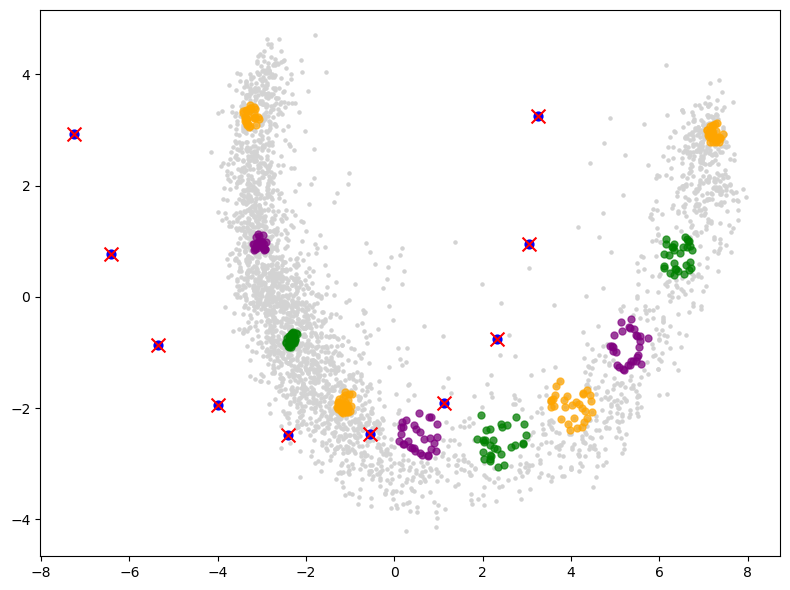

用的color_dict是： {'Granule': '#1f77b4', 'ImmGranule1': '#ff7f0e', 'ImmGranule2': '#2ca02c', 'Nbl1': '#d62728', 'Nbl2': '#9467bd', 'RadialGlia': '#8c564b', 'nIPC': '#e377c2'}
用的celltype_colors是： ['#8c564b', '#ff7f0e', '#ff7f0e', '#1f77b4', '#2ca02c', '#d62728', '#ff7f0e', '#9467bd', '#2ca02c', '#1f77b4', '#1f77b4', '#1f77b4', '#2ca02c', '#1f77b4', '#1f77b4', '#2ca02c', '#ff7f0e', '#1f77b4', '#e377c2', '#1f77b4', '#e377c2', '#ff7f0e', '#e377c2', '#1f77b4', '#1f77b4', '#e377c2', '#d62728', '#2ca02c', '#9467bd', '#e377c2', '#2ca02c', '#9467bd', '#ff7f0e', '#1f77b4', '#8c564b', '#2ca02c', '#e377c2', '#9467bd', '#ff7f0e', '#ff7f0e', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#ff7f0e', '#2ca02c', '#e377c2', '#d62728', '#9467bd', '#2ca02c', '#d62728', '#2ca02c', '#2ca02c', '#e377c2', '#ff7f0e', '#e377c2', '#9467bd', '#2ca02c', '#2ca02c', '#2ca02c', '#ff7f0e', '#1f77b4', '#2ca02c', '#ff7f0e', '#d62728', '#ff7f0e', '#1f77b4', '#2ca02c', '#9467bd', '#e377c2', '#d62728', '#8c564b', '#2ca02c', '#94

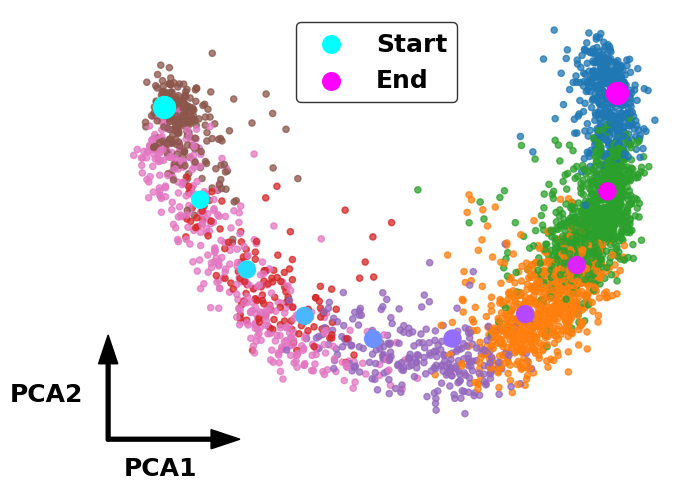

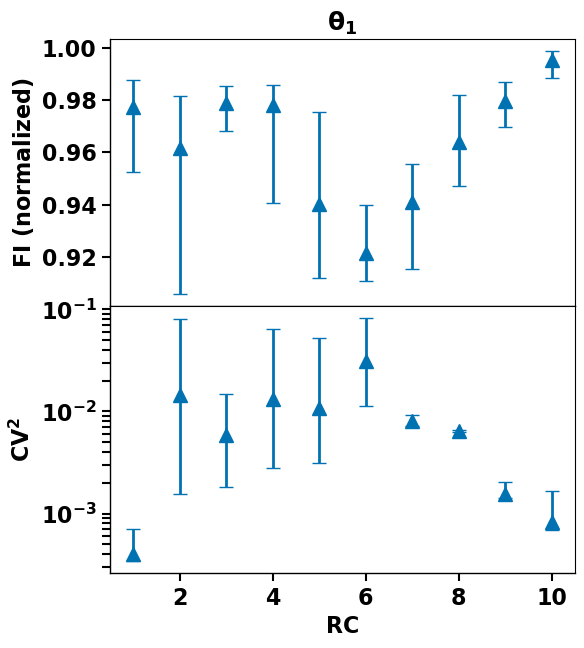

y: [0.00040292 0.01456115 0.00584169 0.01317282 0.01084412 0.03130735
 0.00811391 0.00639794 0.00157132 0.00083534]
max_vals: [0.00071004 0.08091104 0.01467886 0.06424166 0.05203827 0.08145683
 0.0093054  0.00652437 0.00205103 0.00166362]
min_vals: [0.00034252 0.00155608 0.00181202 0.00279705 0.00309927 0.01136657
 0.00712668 0.00628533 0.00142753 0.00068723]
error: [[6.0403225e-05 1.3005065e-02 4.0296689e-03 1.0375775e-02 7.7448455e-03
  1.9940775e-02 9.8722940e-04 1.1260528e-04 1.4378899e-04 1.4810736e-04]
 [3.0711989e-04 6.6349894e-02 8.8371728e-03 5.1068839e-02 4.1194156e-02
  5.0149478e-02 1.1914810e-03 1.2642937e-04 4.7971646e-04 8.2827511e-04]]
y: [0.01390878 0.12070549 0.02607999 0.22965683 0.12027936 0.7831715
 0.36063746 0.50734586 0.07886895 0.01155157]
max_vals: [1.4146709e-01 3.4046647e-01 7.2471790e-02 2.5824165e+00 1.8022710e-01
 1.6293522e+01 9.1703975e-01 9.7109157e-01 1.1763352e-01 1.2405453e-02]
min_vals: [0.00491155 0.00456554 0.01276862 0.04155993 0.09757965 0.0470

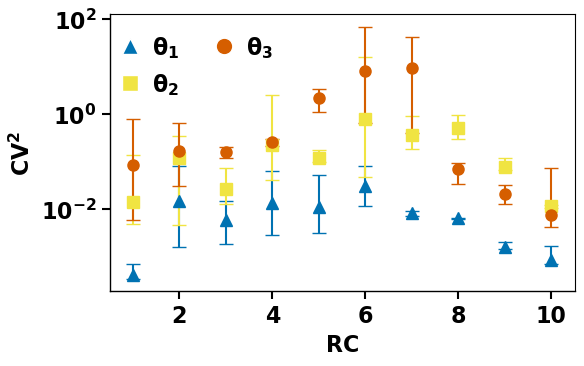

pca_svd_rc_mean_all:
[[[-17.573015   -22.172401     8.400635  ]
  [-17.50941    -22.24881      8.331134  ]
  [-12.565036   -26.552284    -2.844829  ]
  [-16.702667     9.490355    22.40426   ]
  [-17.001888   -21.193848   -11.5218725 ]
  [-17.572157   -22.16953      8.409992  ]
  [-17.353907   -23.763807     2.2627575 ]
  [-18.090174    17.46589    -15.449441  ]
  [-17.45373    -22.334286     8.218517  ]
  [-17.295012   -23.82414      2.0711882 ]
  [-17.375025   -23.371407     4.7836056 ]
  [-16.955433   -18.357239   -15.701019  ]
  [-17.393581   -23.303638     5.0399003 ]
  [-17.464548   -19.72465     13.301301  ]
  [-13.8526945  -24.791096     8.031274  ]
  [-16.602055    -9.276555   -22.567991  ]
  [-17.633654   -22.071445     8.538308  ]
  [-17.524849   -19.646017    13.338318  ]
  [-17.526953   -19.652195    13.326445  ]
  [-17.578983   -22.168827     8.397581  ]
  [-17.7524     -23.029802     5.0475307 ]
  [-18.12606     18.904856   -13.603283  ]
  [-17.58118    -22.157593     8.

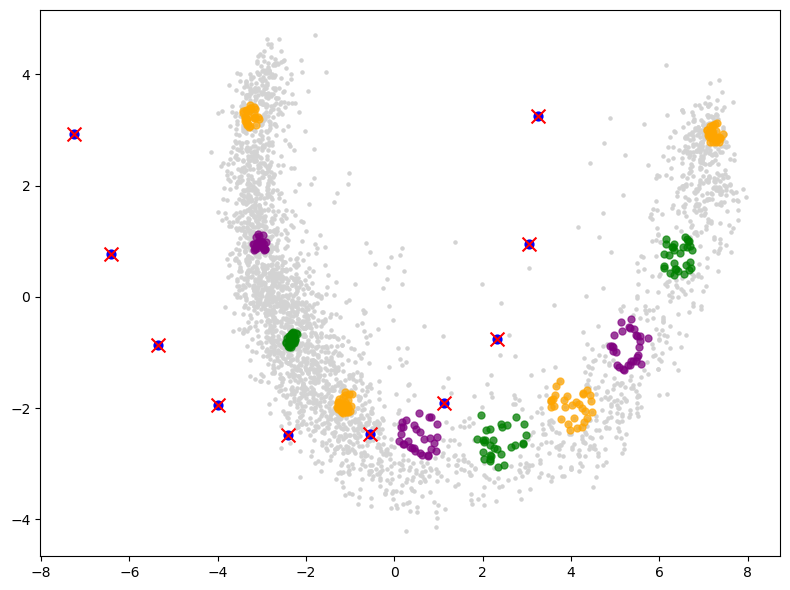

用的color_dict是： {'Granule': '#1f77b4', 'ImmGranule1': '#ff7f0e', 'ImmGranule2': '#2ca02c', 'Nbl1': '#d62728', 'Nbl2': '#9467bd', 'RadialGlia': '#8c564b', 'nIPC': '#e377c2'}
用的celltype_colors是： ['#8c564b', '#ff7f0e', '#ff7f0e', '#1f77b4', '#2ca02c', '#d62728', '#ff7f0e', '#9467bd', '#2ca02c', '#1f77b4', '#1f77b4', '#1f77b4', '#2ca02c', '#1f77b4', '#1f77b4', '#2ca02c', '#ff7f0e', '#1f77b4', '#e377c2', '#1f77b4', '#e377c2', '#ff7f0e', '#e377c2', '#1f77b4', '#1f77b4', '#e377c2', '#d62728', '#2ca02c', '#9467bd', '#e377c2', '#2ca02c', '#9467bd', '#ff7f0e', '#1f77b4', '#8c564b', '#2ca02c', '#e377c2', '#9467bd', '#ff7f0e', '#ff7f0e', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#ff7f0e', '#2ca02c', '#e377c2', '#d62728', '#9467bd', '#2ca02c', '#d62728', '#2ca02c', '#2ca02c', '#e377c2', '#ff7f0e', '#e377c2', '#9467bd', '#2ca02c', '#2ca02c', '#2ca02c', '#ff7f0e', '#1f77b4', '#2ca02c', '#ff7f0e', '#d62728', '#ff7f0e', '#1f77b4', '#2ca02c', '#9467bd', '#e377c2', '#d62728', '#8c564b', '#2ca02c', '#94

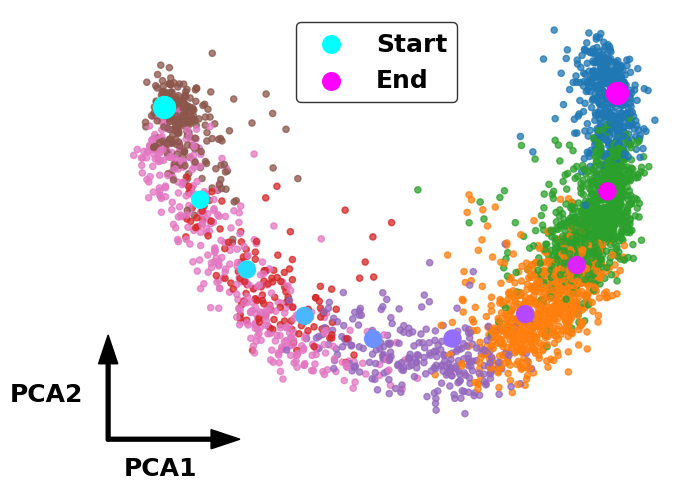

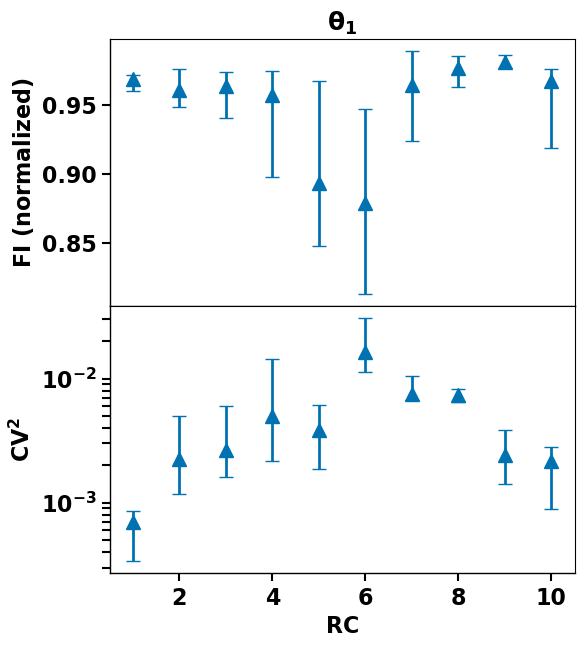

y: [0.00069508 0.00224566 0.00264162 0.00495664 0.0038415  0.01649737
 0.0074648  0.00732786 0.00240473 0.00217113]
max_vals: [0.00085046 0.00499415 0.00601825 0.01438032 0.00612336 0.03052491
 0.01046336 0.00819767 0.00387294 0.00279209]
min_vals: [0.00033779 0.00118414 0.00162109 0.00216717 0.00187779 0.0113569
 0.00669722 0.00649588 0.00141578 0.00089483]
error: [[0.00035728 0.00106152 0.00102053 0.00278947 0.00196372 0.00514047
  0.00076758 0.00083198 0.00098895 0.0012763 ]
 [0.00015538 0.00274849 0.00337663 0.00942368 0.00228185 0.01402755
  0.00299856 0.0008698  0.00146821 0.00062097]]
y: [1.2922918e-02 6.1127729e+00 3.6191184e-02 6.6732727e-02 2.5954452e-01
 8.2338223e+03 3.8839859e+01 1.0693750e-01 3.4084838e-02 7.1198638e-03]
max_vals: [1.56487878e-02 1.63498978e+02 1.41685069e-01 1.01386055e-01
 7.33544886e-01 2.46042672e+05 8.02915588e+02 1.30188107e-01
 3.87293547e-02 7.92020932e-03]
min_vals: [0.00475767 0.01207702 0.02035788 0.04269082 0.1106087  0.11881593
 1.5091206  0.

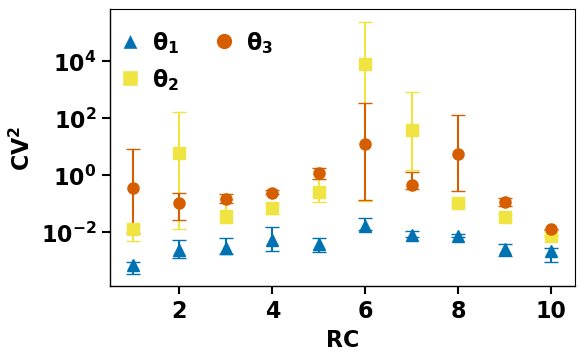

pca_svd_rc_mean_all:
[[[-2.07340069e+01 -1.75154438e+01  1.15890932e+01]
  [-2.07074928e+01 -1.76674442e+01  1.14043036e+01]
  [-1.49579134e+01 -2.53107319e+01  2.57386899e+00]
  [-1.50335855e+01 -2.53911324e+01  5.28024375e-01]
  [-2.02433968e+01 -1.80757236e+01  1.15961208e+01]
  [-2.07524490e+01 -1.74873314e+01  1.15985270e+01]
  [-2.07068405e+01 -1.73773518e+01  1.18427763e+01]
  [-2.11276302e+01 -1.73522243e+01  1.11139736e+01]
  [-2.07288628e+01 -1.75258751e+01  1.15825253e+01]
  [-2.07546558e+01 -1.73912697e+01  1.17381849e+01]
  [-2.11258488e+01 -1.73650513e+01  1.10973167e+01]
  [-1.72006092e+01 -2.25913582e+01  8.04775810e+00]
  [-2.11378899e+01 -1.73365784e+01  1.11188908e+01]
  [-2.10494499e+01 -1.74188862e+01  1.11579552e+01]
  [-1.53355932e+01 -2.43124199e+01  6.68750095e+00]
  [-1.39312792e+01 -2.59797039e+01 -1.40404046e+00]
  [-2.11503716e+01 -1.73161545e+01  1.11269732e+01]
  [-2.11329174e+01 -1.72857666e+01  1.12071009e+01]
  [-2.11438332e+01 -1.72590981e+01  1.12275

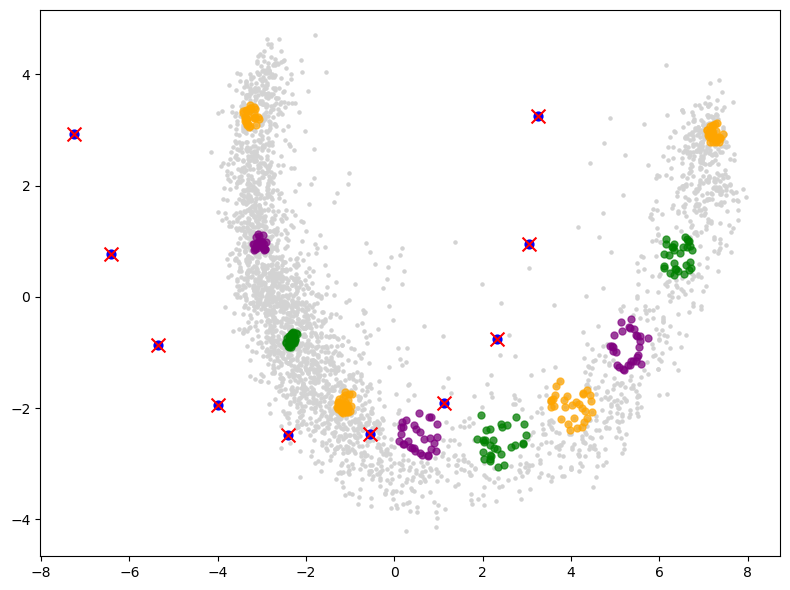

用的color_dict是： {'Granule': '#1f77b4', 'ImmGranule1': '#ff7f0e', 'ImmGranule2': '#2ca02c', 'Nbl1': '#d62728', 'Nbl2': '#9467bd', 'RadialGlia': '#8c564b', 'nIPC': '#e377c2'}
用的celltype_colors是： ['#8c564b', '#ff7f0e', '#ff7f0e', '#1f77b4', '#2ca02c', '#d62728', '#ff7f0e', '#9467bd', '#2ca02c', '#1f77b4', '#1f77b4', '#1f77b4', '#2ca02c', '#1f77b4', '#1f77b4', '#2ca02c', '#ff7f0e', '#1f77b4', '#e377c2', '#1f77b4', '#e377c2', '#ff7f0e', '#e377c2', '#1f77b4', '#1f77b4', '#e377c2', '#d62728', '#2ca02c', '#9467bd', '#e377c2', '#2ca02c', '#9467bd', '#ff7f0e', '#1f77b4', '#8c564b', '#2ca02c', '#e377c2', '#9467bd', '#ff7f0e', '#ff7f0e', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#ff7f0e', '#2ca02c', '#e377c2', '#d62728', '#9467bd', '#2ca02c', '#d62728', '#2ca02c', '#2ca02c', '#e377c2', '#ff7f0e', '#e377c2', '#9467bd', '#2ca02c', '#2ca02c', '#2ca02c', '#ff7f0e', '#1f77b4', '#2ca02c', '#ff7f0e', '#d62728', '#ff7f0e', '#1f77b4', '#2ca02c', '#9467bd', '#e377c2', '#d62728', '#8c564b', '#2ca02c', '#94

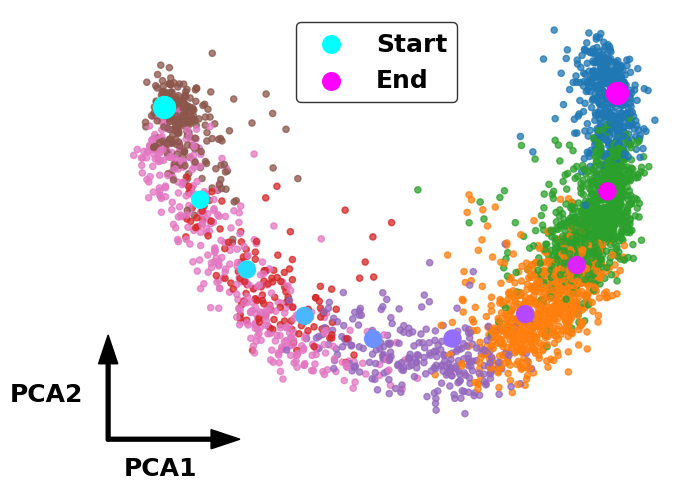

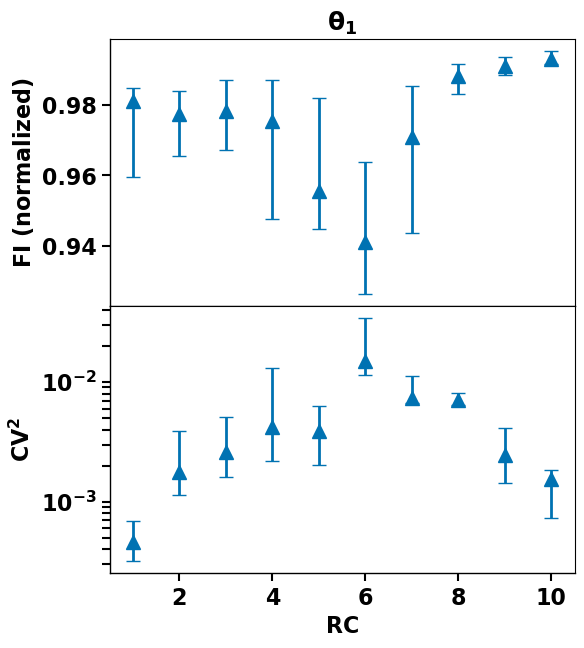

y: [0.00045719 0.00176228 0.00260093 0.00420644 0.00386211 0.01499438
 0.00740662 0.00711442 0.00244691 0.00153501]
max_vals: [0.00068813 0.00392307 0.005051   0.01312545 0.00629207 0.03407658
 0.01132909 0.00813562 0.00414619 0.00183682]
min_vals: [0.00031733 0.00112864 0.00161595 0.00218849 0.00201437 0.01136276
 0.00668016 0.00639878 0.00141562 0.00073059]
error: [[0.00013986 0.00063364 0.00098498 0.00201795 0.00184774 0.00363162
  0.00072646 0.00071564 0.0010313  0.00080442]
 [0.00023094 0.00216079 0.00245007 0.00891901 0.00242997 0.01908219
  0.00392247 0.0010212  0.00169927 0.00030182]]
y: [8.4831836e-03 2.8759840e-01 4.2090435e+00 4.2139444e+00 1.5878919e-01
 3.2325340e+01 6.5170946e+00 2.1651302e-01 5.7129208e-02 1.0835036e-02]
max_vals: [1.05657224e-02 2.41484690e+00 1.10167305e+02 1.24528694e+02
 2.07273960e-01 4.33647034e+02 5.66747513e+01 3.23763758e-01
 7.23678842e-02 1.36267934e-02]
min_vals: [0.00508634 0.00867233 0.0188836  0.04194043 0.09768713 0.10195065
 0.6493478  0

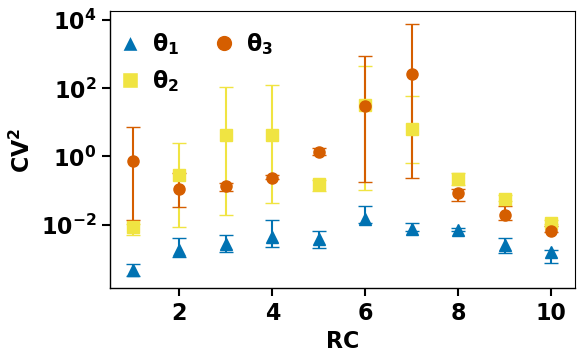

pca_svd_rc_mean_all:
[[[-1.78113365e+01 -2.24524403e+01  7.04564238e+00]
  [-1.81309605e+01 -2.15970345e+01  8.70822620e+00]
  [-1.54830084e+01 -2.50801830e+01 -1.50264847e+00]
  [-1.74196129e+01 -2.38170643e+01  5.49079776e-01]
  [-1.68634167e+01 -2.42068367e+01  8.06953967e-01]
  [-1.78295536e+01 -2.24353714e+01  7.05393314e+00]
  [-1.81318970e+01 -2.10210629e+01  1.00172920e+01]
  [-1.90397282e+01 -2.08845825e+01  8.50410843e+00]
  [-1.78063927e+01 -2.24577236e+01  7.04128885e+00]
  [-1.81687374e+01 -2.15965214e+01  8.63041687e+00]
  [-1.82852001e+01 -2.13410378e+01  9.01157188e+00]
  [-1.68563557e+01 -2.42124271e+01  7.86515653e-01]
  [-1.85446339e+01 -2.12228451e+01  8.75696182e+00]
  [-1.84928303e+01 -2.17405586e+01  7.50734520e+00]
  [-1.48117847e+01 -2.52103233e+01  4.00594902e+00]
  [-1.50376673e+01 -2.52902489e+01 -2.29541230e+00]
  [-1.79724636e+01 -2.19268360e+01  8.19764137e+00]
  [-1.85036411e+01 -2.11481133e+01  9.02050209e+00]
  [-1.82657299e+01 -2.12820148e+01  9.18889

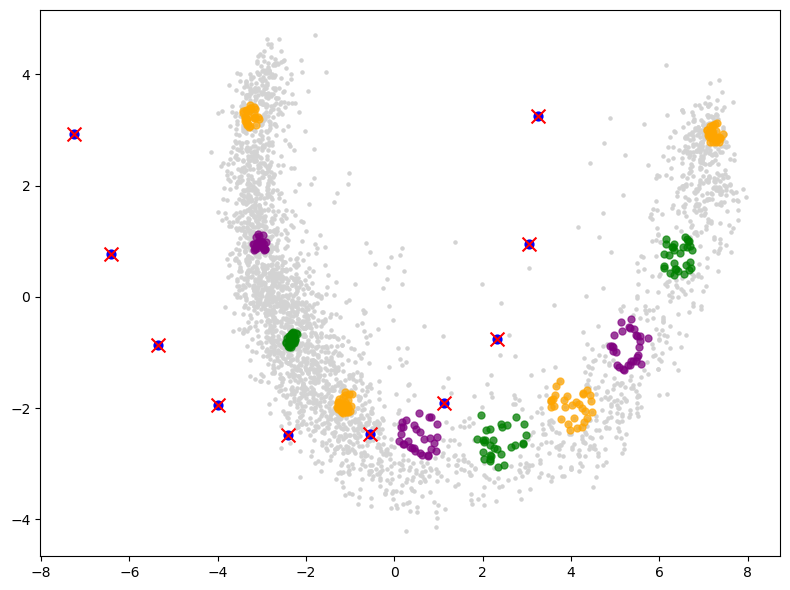

用的color_dict是： {'Granule': '#1f77b4', 'ImmGranule1': '#ff7f0e', 'ImmGranule2': '#2ca02c', 'Nbl1': '#d62728', 'Nbl2': '#9467bd', 'RadialGlia': '#8c564b', 'nIPC': '#e377c2'}
用的celltype_colors是： ['#8c564b', '#ff7f0e', '#ff7f0e', '#1f77b4', '#2ca02c', '#d62728', '#ff7f0e', '#9467bd', '#2ca02c', '#1f77b4', '#1f77b4', '#1f77b4', '#2ca02c', '#1f77b4', '#1f77b4', '#2ca02c', '#ff7f0e', '#1f77b4', '#e377c2', '#1f77b4', '#e377c2', '#ff7f0e', '#e377c2', '#1f77b4', '#1f77b4', '#e377c2', '#d62728', '#2ca02c', '#9467bd', '#e377c2', '#2ca02c', '#9467bd', '#ff7f0e', '#1f77b4', '#8c564b', '#2ca02c', '#e377c2', '#9467bd', '#ff7f0e', '#ff7f0e', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#ff7f0e', '#2ca02c', '#e377c2', '#d62728', '#9467bd', '#2ca02c', '#d62728', '#2ca02c', '#2ca02c', '#e377c2', '#ff7f0e', '#e377c2', '#9467bd', '#2ca02c', '#2ca02c', '#2ca02c', '#ff7f0e', '#1f77b4', '#2ca02c', '#ff7f0e', '#d62728', '#ff7f0e', '#1f77b4', '#2ca02c', '#9467bd', '#e377c2', '#d62728', '#8c564b', '#2ca02c', '#94

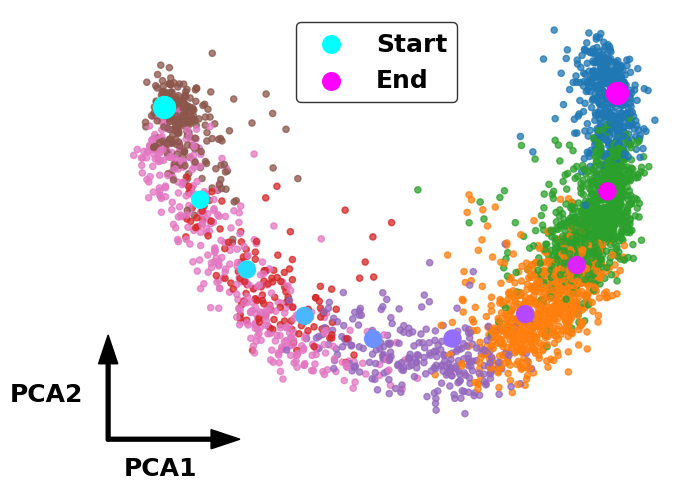

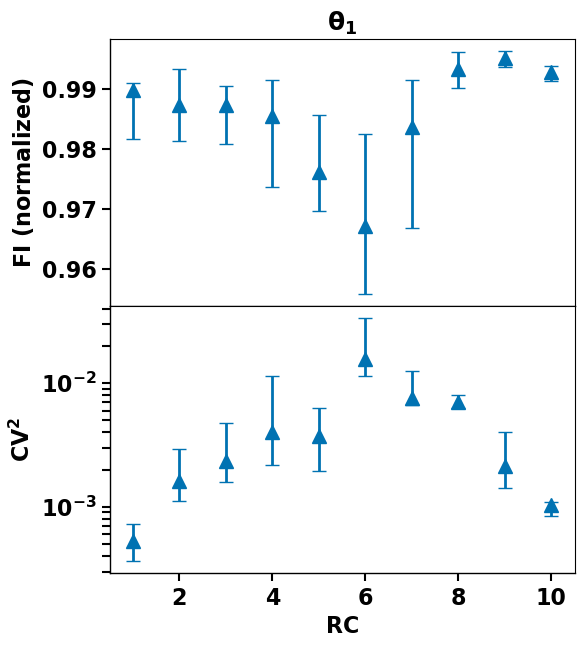

y: [0.00052883 0.00162986 0.00233354 0.00403344 0.00371596 0.0155402
 0.00765061 0.00706576 0.0021548  0.00103296]
max_vals: [0.00072305 0.00294763 0.00476655 0.01132612 0.00634985 0.03338578
 0.01249473 0.00798401 0.00402676 0.00109801]
min_vals: [0.00036402 0.00112468 0.00159897 0.0021721  0.00194263 0.01140955
 0.00663725 0.00629745 0.00140694 0.00085055]
error: [[1.6480996e-04 5.0517393e-04 7.3456846e-04 1.8613406e-03 1.7733341e-03
  4.1306494e-03 1.0133656e-03 7.6830760e-04 7.4786018e-04 1.8241449e-04]
 [1.9421539e-04 1.3177772e-03 2.4330036e-03 7.2926832e-03 2.6338913e-03
  1.7845578e-02 4.8441188e-03 9.1825146e-04 1.8719551e-03 6.5048691e-05]]
y: [9.7121773e-03 4.2835391e-01 3.2445166e-02 8.3357595e-02 1.9293122e-01
 8.7789722e+02 4.9607129e+03 1.7663167e-01 4.6548959e-02 8.1545534e-03]
max_vals: [1.2381942e-02 3.7067008e+00 8.1167668e-02 3.4420580e-01 2.8260770e-01
 2.4116072e+04 1.2444492e+05 2.6406983e-01 5.2368086e-02 9.3308659e-03]
min_vals: [0.0060225  0.00882485 0.0200083

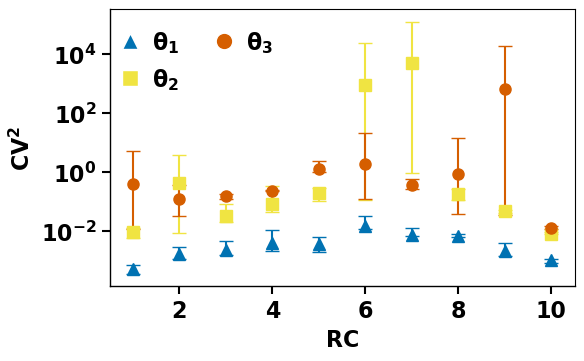

pca_svd_rc_mean_all:
[[[-1.90390453e+01 -2.06639977e+01  9.02833843e+00]
  [-1.90481892e+01 -2.06564026e+01  9.02643681e+00]
  [-1.72921925e+01 -2.39063244e+01 -6.81766629e-01]
  [-1.74112606e+01 -2.38105507e+01 -9.50009346e-01]
  [-1.79513111e+01 -2.31975365e+01  3.25909877e+00]
  [-1.90540810e+01 -2.06772099e+01  8.96615219e+00]
  [-1.89785271e+01 -2.00753117e+01  1.03823948e+01]
  [-1.98401604e+01 -1.98486233e+01  9.13219357e+00]
  [-1.90518970e+01 -2.06746559e+01  8.97668171e+00]
  [-1.90340748e+01 -2.04006176e+01  9.61851406e+00]
  [-1.90505257e+01 -2.06798458e+01  8.96762657e+00]
  [-1.79539165e+01 -2.32114201e+01  3.14386725e+00]
  [-1.97418709e+01 -1.98559608e+01  9.32718372e+00]
  [-1.97719917e+01 -1.95631771e+01  9.86648464e+00]
  [-1.67765541e+01 -2.37518902e+01  5.03902292e+00]
  [-1.78986931e+01 -2.34244175e+01 -1.38933015e+00]
  [-1.90555954e+01 -2.06884098e+01  8.93704605e+00]
  [-1.98022594e+01 -1.95291786e+01  9.87312698e+00]
  [-1.97914314e+01 -1.95228672e+01  9.90726

In [4]:
k_nei_list = [10]
K_list = [3]
L_list = [3, 6, 10, 15]

param_combinations = list(itertools.product(k_nei_list, K_list, L_list))

for k_nei, K, L in param_combinations:
    [k_nei, K, L] = [k_nei, K, L]
    data_name = "DG_bin_ppt"
    print(f"[k_nei, K, L] = [{k_nei}, {K}, {L}]")
    figure_path= f"/home/linux/桌面/Is single cell sloppy?/14_画图/figure/cv_2/{data_name}/" + str([k_nei,K,L]) + "/"

    [pca_dim, k_rc, d_pca, nrc] = [50, 30, 2, 10]

    clusters_name = "ClusterName"
    root_cluster = "RadialGlia"
    loc_path_graph = 'upper left'
    basis = "pca"

    t_list = np.array(['RadialGlia','nIPC', 'Nbl1', 'Nbl2', 'ImmGranule1', 'ImmGranule2', 'Granule' ])
    branch_name = t_list[-1]

    adata0 = scv.read(data_path+data_name+'.h5ad', cache=True)
    adata = adata0.copy()
    scv.pp.pca(adata, n_comps=pca_dim)
    scv.pp.neighbors(adata, n_neighbors=k_nei)
    scv.pp.moments(adata, n_pcs=pca_dim, n_neighbors=k_nei)
    scv.tl.velocity(adata)
    print(adata)

    for nrc in [10]:
        # average_path = np.load(path_path + f'{data_name}_{branch_name}_P2M_rc_nrc_{nrc}_dpca_{d_pca}.npy') 
        average_path = np.load(path_path + f'{data_name}_P2M_rc_nrc_{nrc}_dpca_{d_pca}.npy') 
        cell_arr, nearest_cell = find_nearest_indices_voronoi(adata = adata, path0= average_path, rc_distance= "X_pca", n_nei=k_rc, dim_n=d_pca)            
        average_path[:,0] = -average_path[:,0]


        # fig = sc.pl.embedding(
        #     adata,
        #     # color=[clusters_name, "paga"],
        #     color=[clusters_name],
        #     basis="pca",
        #     color_map=cmap,
        #     return_fig=True
        # )

        X_pca = adata.obsm['X_pca']
        row = np.array([np.ones((k_nei,))*i for i in range(adata.shape[0])]).flatten()
        col = adata.uns['neighbors']['indices'].flatten()
        w_val = np.array([np.linalg.norm(X_pca[int(i),:]-X_pca[int(j),:]) for i,j in zip(row,col)])
        adj_val = np.ones(col.shape)
        A_mat = csr_matrix((adj_val, (row, col)), shape=(adata.shape[0], adata.shape[0]))
        A = A_mat
        W_mat = csr_matrix((w_val, (row, col)), shape=(adata.shape[0], adata.shape[0]))
        dc=np.mean(w_val)
        cell_nei=adata.uns['neighbors']['indices']
        nei_w=[]
        rho_arr=[]
        for ni in adata.uns['neighbors']['indices']:
            dij=np.array([np.linalg.norm(X_pca[int(ni[0]),:]-X_pca[int(i),:]) for i in ni[1:]])
            rho=np.sum(np.exp(-dij**2/dc**2))
            nei_w.append(np.exp(-dij**2/dc**2)/np.sum(np.exp(-dij**2/dc**2)))
            rho_arr.append(rho)
            
        rho_arr=np.array(rho_arr)/np.amax(rho_arr)
        nei_w=np.array(nei_w)
        nei_w=np.hstack((np.ones((nei_w.shape[0],1)),nei_w))/2

        def smooth_func(X_val,cell_nei=cell_nei,nei_w=nei_w):
            X_s=X_val.copy()
            for ci in range(len(X_val)):
                X_s[ci]=np.dot(X_val[cell_nei[ci,:]],nei_w[ci,:])
            return X_s

        if basis == "umap":
            X_umap = adata.obsm['X_umap']
            X_plt = X_umap[:,0]
            Y_plt = X_umap[:,1]
            X_min = np.min(X_plt)
            X_max = np.max(X_plt)
            Y_min = np.min(Y_plt)
            Y_max = np.max(Y_plt)
            X_len = (X_max-X_min)/5
            Y_len = (Y_max-Y_min)/5
            wid = min(X_len,Y_len)/30
            X_ori = X_min-wid*10
            Y_ori = Y_min-wid*10
        elif basis == "pca":
            X_umap = adata.obsm['X_pca'][:, :2]
            X_plt = X_umap[:,0]
            Y_plt = X_umap[:,1]
            X_min = np.min(X_plt)
            X_max = np.max(X_plt)
            Y_min = np.min(Y_plt)
            Y_max = np.max(Y_plt)
            X_len = (X_max-X_min)/5
            Y_len = (Y_max-Y_min)/5
            wid = min(X_len,Y_len)/30
            X_ori = X_min-wid*10
            Y_ori = Y_min-wid*10

        X = torch.tensor(adata.layers['Ms'], dtype=torch.float32) 
        Encoder_path = "/home/linux/桌面/Is single cell sloppy?/11_PAGA_spectrum/encoder/"
        # for pca in [X_pca, eigengene, hotspot]:

        model_path = Encoder_path + data_name+' '+str([k_nei,K,L])+'/'
        eigengene = np.load(f"/home/linux/桌面/Is single cell sloppy?/14_画图/Eigengene&hotspot/{data_name}/cell_eigengene_X.npy")
        # hotspot = np.load(f"/home/linux/桌面/Is single cell sloppy?/14_画图/Eigengene&hotspot/{data_name}/cell_hs_X.npy")
        model_name = f"{model_path}encoder.pt"
        model = torch.load(f'{model_name}')
        mu, sigma = model(torch.tensor(X))
        mu_learned = mu.detach().numpy()

        sigma_learned = sigma.detach().numpy()
        Fisher_g=np.zeros((X.shape[0],L*2,L*2))
        for i in range(X.shape[0]):
            for j in range(L):
                Fisher_g[i,j,j]=1/sigma_learned[i,j]**2
                Fisher_g[i,L+j,L+j]=2/sigma_learned[i,j]**2
        Fisher_g_diag = np.zeros([X.shape[0],L*2])
        for i in range(X.shape[0]):
            Fisher_g_diag[i] = np.diag(Fisher_g[i])
        ## 1_1这一步用了一个神经网络 pca -> Z(mu,sigma), 然后求出这个网络的pZ_pEg。
        for pca in [eigengene]:
            print("pca.shape:", pca.shape)
            reset_seeds(0) # 0
            model = nn.Sequential(
                nn.Linear(pca.shape[1], 128),
                nn.ReLU(),
                nn.Linear(128,64),
                nn.ReLU(),
                nn.Linear(64,2*L),
            )
            loss_fn = nn.MSELoss()
            optimizer = SGD(model.parameters(), lr=0.01, weight_decay=0.001)#, momentum=0.2
            x_in=torch.tensor(pca, dtype=torch.float32)
            latent_z = np.hstack((mu_learned,sigma_learned))
            x_out=torch.tensor(latent_z.astype(np.float32))
            for epoch in range(500): # 200
                # break
                optimizer.zero_grad()
                output = model(x_in)
                loss = loss_fn(output,x_out) 
                loss.backward()
                optimizer.step()
            pZ_ppca = p_out_p_in(pca, model, dim_out = 2 * L)

            ### 链式法则（已知FI_Z），求出FI_pca。
            FI_pca = np.einsum("ijk,ij,ijh->ikh",pZ_ppca, Fisher_g_diag, pZ_ppca)
            print("FI_pca.shape:", FI_pca.shape)
            # FI_Eg_diag = FI_Eg[:, range(eigengene.shape[1]), range(eigengene.shape[1])]
            # U_FI_Eg[i]的列向量是特征向量。Ax = /lamba x (从这可以看出x是列向量)
            # 不过U_FI_Eg[i]的行向量和列向量的模长都是1.而且行和行彼此正交。列和列彼此正交。这是因为UU_T = I. U是正交矩阵。
            U_FI_Eg, S_FI_Eg, Vt_FI_Eg = np.linalg.svd(FI_pca, full_matrices=False)
            print("svd后(U_FI_Eg, S_FI_Eg, Vt_FI_Eg)：",U_FI_Eg.shape, S_FI_Eg.shape, Vt_FI_Eg.shape)
            print("S_FI_Eg:", S_FI_Eg)

            # rc_path(adata, mu_learned, sigma_learned, average_path, basis, k_nei, data_name)
            cell_arr_plot(average_path, cell_arr, X_umap)
            rc_path_celltype(adata, average_path, basis, data_name, save = save, figure_path = figure_path, branch_name  = branch_name)
                
            dim = 3
            # U_FI_Eg和pca的各列都是正交的才可以这么算。cell_i_的pca坐标（向量）点积u1得到的就是u1的坐标，这其实就是在u1上做投影。
            # NOTE:这可能是为什么eigengene和hotspot不行的原因，eigengene的各坐标系间不是正交的。
            pca_svd_rc_variance_all, pca_svd_rc_mean_all= compute_variances(U_FI_Eg, pca, cell_arr, k_rc= k_rc, L = L, simple=dim/2, cv= True)
            pca_svd_rc_variance_average = np.array([np.mean(arr, axis=0) for arr in pca_svd_rc_variance_all])
            # plot_all_variances_odd(pca_svd_rc_variance_all, share_y = False)
            FI_VAR_double_grid(S_FI_Eg, pca_svd_rc_variance_all, pca, L = 0.5, cell_arr = cell_arr, norm=True, simple= True, 
                            save = save, figure_path = figure_path, branch_name  = branch_name)

            exclude_indices = []
            all_indices = list(range(len(pca_svd_rc_variance_all)))
            keep_indices = [i for i in all_indices if i not in exclude_indices]
            new_array = np.array(pca_svd_rc_variance_all)[keep_indices]

            variance_along_rc(cell_arr, new_array, dim = dim, save = save, figure_path = figure_path, branch_name  = branch_name)

            print("pca_svd_rc_mean_all:")
            print(np.array(pca_svd_rc_mean_all))

In [5]:
# 幂法
# print(top_k_eigenpairs(FI_pca, k=7))
# print("U_FI_Eg", U_FI_Eg)
# print("S_FI_Eg", S_FI_Eg)

# # PART 3------show一下RC path
# rc_num = average_path.shape[0]
# cells_visual = adata.obsm[f'X_pca'][:, :2]
# # 只取3种颜色，然后循环使用
# base_colors = ['orange', 'green', 'purple']
# plt.figure(figsize=(8,6))
# plt.scatter(cells_visual[:,0], cells_visual[:,1], s=5, color='lightgrey', label='All cells')
# plt.scatter(cells_visual[nearest_cell,0], cells_visual[nearest_cell,1], s=40, c='blue', label='Path points')

# for rc_i in range(rc_num):
#     color = base_colors[rc_i % 3]  # 每3种颜色循环
#     plt.scatter(cells_visual[nearest_cell[rc_i],0], cells_visual[nearest_cell[rc_i],1], s=100, c='red', marker='x')
#     plt.scatter(cells_visual[cell_arr[rc_i],0], 
#                 cells_visual[cell_arr[rc_i],1],
#                 s=25, c=[color], alpha=0.7, label=f'RC {rc_i}')

# # plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)
# plt.title('Nearest 30 cells for all RCs (3-color cycle)')
# plt.tight_layout()
# plt.show() 

# # PART 3------show一下RC path
# rc_num = average_path.shape[0]
# cells_visual = adata.obsm[f'X_{basis}'][:, :2]
# # 只取3种颜色，然后循环使用
# base_colors = ['orange', 'green', 'purple']
# plt.figure(figsize=(8,6))
# plt.scatter(cells_visual[:,0], cells_visual[:,1], s=5, color='lightgrey', label='All cells')
# plt.scatter(cells_visual[nearest_cell,0], cells_visual[nearest_cell,1], s=40, c='blue', label='Path points')

# for rc_i in range(rc_num):
#     color = base_colors[rc_i % 3]  # 每3种颜色循环
#     plt.scatter(cells_visual[nearest_cell[rc_i],0], cells_visual[nearest_cell[rc_i],1], s=100, c='red', marker='x')
#     plt.scatter(cells_visual[cell_arr[rc_i],0], 
#                 cells_visual[cell_arr[rc_i],1],
#                 s=25, c=[color], alpha=0.7, label=f'RC {rc_i}')

# # plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)
# plt.title('Nearest 30 cells for all RCs (3-color cycle)')
# plt.tight_layout()
# plt.show()


# pca_svd_rc_variance_all = compute_variances(U_FI_Eg, pca, cell_arr, k_rc= k_rc, L = L)
# pca_svd_rc_variance_average = np.array([np.mean(arr, axis=0) for arr in pca_svd_rc_variance_all])
# plot_all_variances(pca_svd_rc_variance_all)
# eigengene_value(S_FI_Eg, pca, L, cell_arr, norm = True)

# pca_svd_rc_variance_all = compute_variances(U_FI_Eg, pca, cell_arr, k_rc= k_rc, L = L)
# pca_svd_rc_variance_average = np.array([np.mean(arr, axis=0) for arr in pca_svd_rc_variance_all])
# plot_all_variances(pca_svd_rc_variance_all)
# eigengene_value(S_FI_Eg, pca, L, cell_arr, norm = True)
# eigengene_value(S_FI_Eg, pca, L, cell_arr, norm = True, simple= True)

# eigengene_value(S_FI_Eg, pca, L, cell_arr, norm = False)
# eigengene_value(S_FI_Eg, pca, L, cell_arr, norm = False, simple= True)
# eigengene_value_sum(S_FI_Eg, pca, L, cell_arr)
# eigengene_value(np.array(pca_svd_rc_variance_all), X_pca, L, cell_arr)

# FI_VAR_double_grid(S_FI_Eg, pca_svd_rc_variance_all, pca, L, cell_arr, norm=True)

In [6]:
pca.shape

(3139, 3)